# So sánh Feature Extraction giữa ba nguồn SVMG

Notebook tổng hợp kết quả thực tế của Seafar, Hohai 6-DOF và Southampton KCS. Mỗi nguồn/session/segment được giữ độc lập. Các 30 feature vẫn là candidate, không thay đổi contract 14 feature hiện hành.

## 1. Nạp kết quả CLI và kiểm tra khả năng tái lập

Notebook đọc các summary và Parquet đã được tạo bởi `ml.features.run`; không triển khai lại công thức. Đường dẫn được xác định tương đối từ repository.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "ml/features").is_dir())
sys.path.insert(0, str(ROOT))
from ml.features.spec import FEATURE_NAMES
summary = json.loads((ROOT / "ml/reports/features/feature_extraction_summary.json").read_text(encoding="utf-8"))
datasets = ["seafar", "hohai", "southampton"]
values = {name: pd.read_parquet(ROOT / "ml/data/features" / name / "feature_values.parquet") for name in datasets}
metadata = {name: pd.read_parquet(ROOT / "ml/data/features" / name / "feature_metadata.parquet") for name in datasets}
print("Thứ tự feature đúng spec:", len(FEATURE_NAMES), "tên")
print("Phiên bản extractor:", summary["feature_extractor_version"], "| Python:", summary["environment"]["python"])

Thứ tự feature đúng spec: 30 tên
Phiên bản extractor: 0.1.0 | Python: 3.14.6


## 2. So sánh số phiên, cửa sổ và mức độ đầy đủ

`candidate_windows_60s` là số endpoint đã đủ lịch sử tối thiểu 60 giây. Cột 180 giây đếm endpoint đủ độ dài theo segment, không khẳng định mọi feature 180 giây đều hợp lệ nếu có missing/gap.

In [2]:
rows = []
for name in datasets:
    item = summary["datasets"][name]
    rows.append({
        "Nguồn": name.capitalize(), "Sessions": item["sessions"], "Segments": item["segments"],
        "Cửa sổ ứng viên 60 giây": item["candidate_windows_60s"],
        "Endpoint đủ 180 giây": item["candidate_windows_180s"],
        "Đủ 30 feature": item["complete_30_feature_rows"],
        "Roll-only 60s": item["complete_practical_subsets"]["roll_only_60"],
        "Angle-only 23": item["complete_practical_subsets"]["angle_only_23_without_gyro_or_period"],
        "Thời gian trích xuất (giây)": round(item["elapsed_seconds"], 3),
        "Peak Python memory (MB)": round(item["peak_traced_python_memory_mb"], 3),
    })
display(pd.DataFrame(rows).set_index("Nguồn"))

,Sessions,Segments,Cửa sổ ứng viên 60 giây,Endpoint đủ 180 giây,Đủ 30 feature,Roll-only 60s,Angle-only 23,Thời gian trích xuất (giây),Peak Python memory (MB)
Nguồn,,,,,,,,,
Seafar,1,24,1384,1318,0,1384,1318,59.915,22.313
Hohai,21,21,1764,1512,0,1764,1512,73.015,4.553
Southampton,47,47,277,34,0,277,34,2.720,2.623


## 3. So sánh validity và tính khả dụng

Thiếu gyro không được mã hóa thành giá trị số. `VALID` phản ánh tính toán đủ điều kiện dữ liệu, còn `UNVERIFIED_SIGNAL_MAPPING` phản ánh mapping chưa đủ căn cứ. Hàng chỉ hợp lệ một phần không được dùng như hàng đủ 30 feature.

In [3]:
status_rows = []
for name in datasets:
    item = summary["datasets"][name]
    for feature, counts in item["feature_status_counts"].items():
        status_rows.append({"Nguồn": name.capitalize(), "Feature": feature, **counts})
status = pd.DataFrame(status_rows)
selected = status[status["Feature"].isin(["gyro_x_rms_60", "gyro_y_rms_60", "roll_period_est_180", "roll_rms_60"])]
display(selected.set_index(["Nguồn", "Feature"]))
for name in datasets:
    print(name.capitalize(), "— complete 30:", summary["datasets"][name]["complete_30_feature_rows"], "— gyro:", summary["datasets"][name]["source_gyro_status"])

VALID  MISSING_SOURCE_SIGNAL  \
Nguồn       Feature                                             
Seafar      roll_rms_60           1384                      0   
            gyro_x_rms_60            0                      0   
            roll_period_est_180   1285                      0   
            gyro_y_rms_60            0                      0   
Hohai       roll_rms_60           1764                      0   
            gyro_x_rms_60            0                   1764   
            roll_period_est_180   1512                      0   
            gyro_y_rms_60            0                   1764   
Southampton roll_rms_60            277                      0   
            gyro_x_rms_60            0                      0   
            roll_period_est_180     34                      0   
            gyro_y_rms_60            0                      0   

                                 INSUFFICIENT_WINDOW  INVALID_INPUT  \
Nguồn       Feature                                                   
Seafar      roll_rms_60                            0              0   
            gyro_x_rms_60                          0              0   
            roll_period_est_180                   66              0   
            gyro_y_rms_60                          0              0   
Hohai       roll_rms_60                            0              0   
            gyro_x_rms_60                          0              0   
            roll_period_est_180                  252              0   
            gyro_y_rms_60                          0              0   
Southampton roll_rms_60                            0              0   
            gyro_x_rms_60                          0              0   
            roll_period_est_180                  243              0   
            gyro_y_rms_60                          0              0   

                                 UNDEFINED_MATHEMATICALLY  \
Nguồn       Feature                                         
Seafar      roll_rms_60                                 0   
            gyro_x_rms_60                               0   
            roll_period_est_180                        33   
            gyro_y_rms_60                               0   
Hohai       roll_rms_60                                 0   
            gyro_x_rms_60                               0   
            roll_period_est_180                         0   
            gyro_y_rms_60                               0   
Southampton roll_rms_60                                 0   
            gyro_x_rms_60                               0   
            roll_period_est_180                         0   
            gyro_y_rms_60                               0   

                                 UNVERIFIED_SIGNAL_MAPPING  
Nguồn       Feature                                         
Seafar      roll_rms_60                                  0  
            gyro_x_rms_60                             1384  
            roll_period_est_180                          0  
            gyro_y_rms_60                             1384  
Hohai       roll_rms_60                                  0  
            gyro_x_rms_60                                0  
            roll_period_est_180                          0  
            gyro_y_rms_60                                0  
Southampton roll_rms_60                                  0  
            gyro_x_rms_60                              277  
            roll_period_est_180                          0  
            gyro_y_rms_60                              277

Seafar — complete 30: 0 — gyro: UNVERIFIED_SIGNAL_MAPPING
Hohai — complete 30: 0 — gyro: MISSING_SOURCE_SIGNAL
Southampton — complete 30: 0 — gyro: UNVERIFIED_SIGNAL_MAPPING


## Rà soát nhóm period và tập angle-only 23

Kiểm tra cuối phát hiện lỗi gán ngược mảng tín hiệu Roll và timestamp ở cửa sổ 180 giây; do đó kết quả cũ có crossing count tính trên thời gian và period bị báo undefined. Đã sửa lỗi và chạy lại extraction. Period dùng Roll đã trừ mean của cửa sổ; không detrend. Định nghĩa bám theo proposal đang chờ nhóm phê duyệt. Subset 23 loại trừ toàn bộ Group E theo thiết kế, dù các period feature hiện có cửa sổ `VALID`. Chi tiết số liệu thực và các giới hạn nằm trong [báo cáo rà soát chu kỳ và subset](../reports/features/feature_period_subset_review.md).

In [4]:
period_rows = []
for name in datasets:
    joined = metadata[name].merge(values[name], on="window_id")
    valid = joined[joined["roll_period_est_180"].notna()]
    if len(valid):
        row = valid.sort_values("window_end_seconds").iloc[-1]
        period_rows.append({"Nguồn": name.capitalize(), "Session": row.session_id, "Segment": row.segment_id,
            "Endpoint (giây)": row.window_end_seconds, "Zero-crossings": row.roll_zero_crossings_180,
            "Period median (giây)": row.roll_period_est_180, "CV period": row.roll_period_cv_180})
display(pd.DataFrame(period_rows).set_index("Nguồn"))

,Session,Segment,Endpoint (giây),Zero-crossings,Period median (giây),CV period
Nguồn,,,,,,
Seafar,seafar_session_001,segment_031,14332.0,25.0,11.550000,0.662373
Hohai,Berth_D_T9_Type_A,segment_000,892.0,198.0,1.790206,0.155701
Southampton,southampton_run_14,segment_000,512.0,310.0,0.703950,2.655624


## 4. Phân bố feature theo nguồn

Hình so sánh chỉ hiển thị các quan sát hữu hạn trong từng feature column. Do đơn vị/cảm biến/tần số nguồn có thể khác nhau, tương quan phân bố không tự chứng minh các tập dữ liệu tương đương.

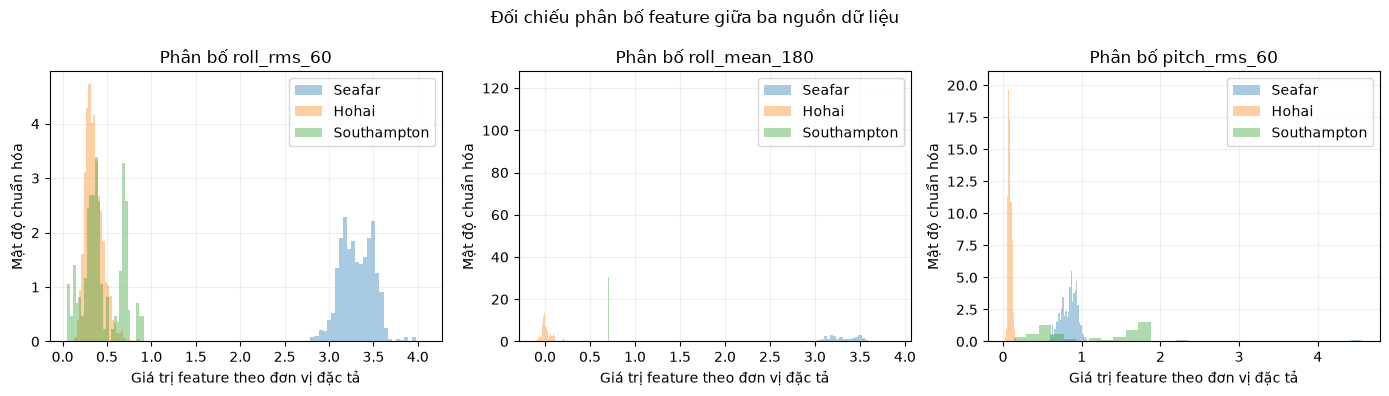

Hình đã lưu: ml/data/features/diagnostics/notebook_feature_dataset_comparison.png


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, feature in zip(axes, ["roll_rms_60", "roll_mean_180", "pitch_rms_60"]):
    for name in datasets:
        series = pd.to_numeric(values[name][feature], errors="coerce").dropna()
        if len(series):
            ax.hist(series, bins=28, density=True, alpha=0.38, label=name.capitalize())
    ax.set_title(f"Phân bố {feature}")
    ax.set_xlabel("Giá trị feature theo đơn vị đặc tả")
    ax.set_ylabel("Mật độ chuẩn hóa")
    ax.grid(True, alpha=0.2)
    ax.legend()
fig.suptitle("Đối chiếu phân bố feature giữa ba nguồn dữ liệu")
fig.tight_layout()
out = ROOT / "ml/data/features/diagnostics/notebook_feature_dataset_comparison.png"
out.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(out, dpi=120)
plt.show()
print("Hình đã lưu:", out.relative_to(ROOT))

## 5. Độ nhạy với cấu hình lọc

So sánh sensitivity dùng cùng endpoint và feature hợp lệ ở cả hai cấu hình: baseline Butterworth bậc 4, cutoff 4 Hz và thí nghiệm thay thế cutoff 3 Hz. Dữ liệu thay thế được xử lý trong bộ nhớ, không ghi đè Parquet baseline. Seafar không có bước giảm mẫu 50→10 Hz; Hohai và Southampton có thể so sánh trên segment đại diện.

In [6]:
stability_rows = []
for name, item in summary["filter_stability"].items():
    stability_rows.append({"Nguồn": name.capitalize(), "Trạng thái": item["status"],
        "Segment đại diện": item.get("representative_segment_id", "—"),
        "Endpoint chung": item.get("matched_windows", 0),
        "Nguồn tham chiếu": item.get("raw_reference", item.get("reason_vi", "—"))})
display(pd.DataFrame(stability_rows).set_index("Nguồn"))
for name in ["hohai", "southampton"]:
    item = summary["filter_stability"][name]
    if item.get("status") == "COMPARED":
        top = item["most_sensitive_features_by_normalized_difference"][:5]
        display(pd.DataFrame(top, columns=["Feature nhạy nhất", "Sai khác chuẩn hóa trung bình"]))

,Trạng thái,Segment đại diện,Endpoint chung,Nguồn tham chiếu
Nguồn,,,,
Seafar,NOT_APPLICABLE_NO_50_TO_10_FILTER,—,0,Tần số nguồn không cao hơn tần số đích; không ...
Hohai,COMPARED,segment_000,84,ml/data/raw/hohai/6-DOF ship motions Data.xlsx...
Southampton,COMPARED,segment_000,46,ml/data/raw/southampton/Raw Data_IMU/Run14_IMU...


,Feature nhạy nhất,Sai khác chuẩn hóa trung bình
0,roll_p95_trend_slope_180,0.081996
1,roll_mean_shift_180,0.036958
2,roll_median_180,0.023544
3,roll_segment_mean_std_180,0.018970
4,roll_iqr_60,0.018788


,Feature nhạy nhất,Sai khác chuẩn hóa trung bình
0,roll_period_est_180,0.269865
1,roll_diff_rms_60,0.237520
2,roll_zero_crossings_180,0.125189
3,roll_period_cv_180,0.073425
4,roll_peak_to_peak_60,0.065339


## 6. Kết luận và giải thích kỹ thuật phục vụ vấn đáp

**Quan sát:** mọi nguồn có cửa sổ angle-only nhưng không có hàng đủ cả 30 feature do thiếu hoặc chưa xác nhận gyro canonical; Southampton có ít endpoint đủ 180 giây hơn rõ rệt. **Giả định:** 10 Hz, coverage 95%, cửa sổ `(t-W,t]` và các quy ước toán học hiện tại là baseline vận hành, chưa được phê duyệt như chuẩn khoa học. **Quyết định kỹ thuật:** giữ missingness và validity riêng; không nối session; metadata không nằm trong feature vector. **Giới hạn:** sensitivity trên một segment đại diện cho mỗi nguồn không đủ chứng minh cấu hình lọc tối ưu. **Bước kế tiếp:** nhóm duyệt công thức/mapping gyro, mở rộng sensitivity qua nhiều session, rồi chuẩn bị labeling có kiểm soát; chưa train mô hình.

Sau sửa lỗi gán đảo tín hiệu/timestamp, period không còn undefined toàn bộ: Seafar còn một số cửa sổ thiếu crossing/chu kỳ; Hohai và Southampton có period hợp lệ trên các cửa sổ đủ 180 giây lần chạy này. Giá trị `VALID` vẫn cần đánh giá ổn định vì CV có thể cao.